# U-Net — Experiments on ISBI 2012
**Master Artificial Intelligence and Applications | Practical work**

This notebook evaluates the original valid-convolution U-Net implemented in `src/unet.py` on electron microscopy images of neuronal structures. It uses our existing TIFF loader, weighted cross-entropy, He initialization and elastic deformation modules.

**Protocol:** 24 training slices, 6 contiguous validation slices from the training stack, and 30 independent test-stack slices (provided labels). Class 0 = neuronal interiors / non-membranes; class 1 = membranes / black annotated pixels. The official labels are inverted for our foreground convention. This is a binary semantic segmentation experiment, not an exact reproduction of the 2015 leaderboard.

References: [Ronneberger et al. (2015)](https://arxiv.org/abs/1505.04597) · [ISBI 2012 dataset and annotation convention](https://imagej.net/events/isbi-2012-segmentation-challenge).

Run cells in order using the project's `.venv` kernel. No results are pre-filled.

In [1]:
import sys
from pathlib import Path
import random
import time
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Locate the root regardless of whether Jupyter starts in notebooks/ or root.
current = Path.cwd().resolve()
ROOT = next((p for p in [current, *current.parents]
             if (p / 'src' / 'unet.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open the project folder in VS Code and run the notebook from it.')
sys.path.insert(0, str(ROOT))
from src.unet import UNet
from src.dataset import load_tiff_stack
from src.loss import WeightedCrossEntropyLoss
from src.initialization import initialize_weights
from src.augmentation import elastic_deformation

DATA = ROOT / 'data' / 'ISBI-2012-challenge'
RESULTS = ROOT / 'results'
CHECKPOINTS = ROOT / 'checkpoints'
RESULTS.mkdir(exist_ok=True)
CHECKPOINTS.mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('mps' if torch.backends.mps.is_available() else
                      'cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'mps':
    torch.mps.manual_seed(SEED)
print('Project:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', device)

Project: /Users/mac/Desktop/TPs/S3/Generative/Synthèse UNET
PyTorch: 2.15.0 | Device: mps


## 1. Dataset exploration
The source TIFF stacks contain grayscale slices. According to the dataset documentation, segmented structures are white and the remaining pixels (mostly membranes) are black. We treat black pixels as the foreground class for membrane Dice and IoU. Only training images are visualized at this stage.

Training images: (30, 512, 512) uint8
Raw label values: [  0 255]
Intensity range: 0 255


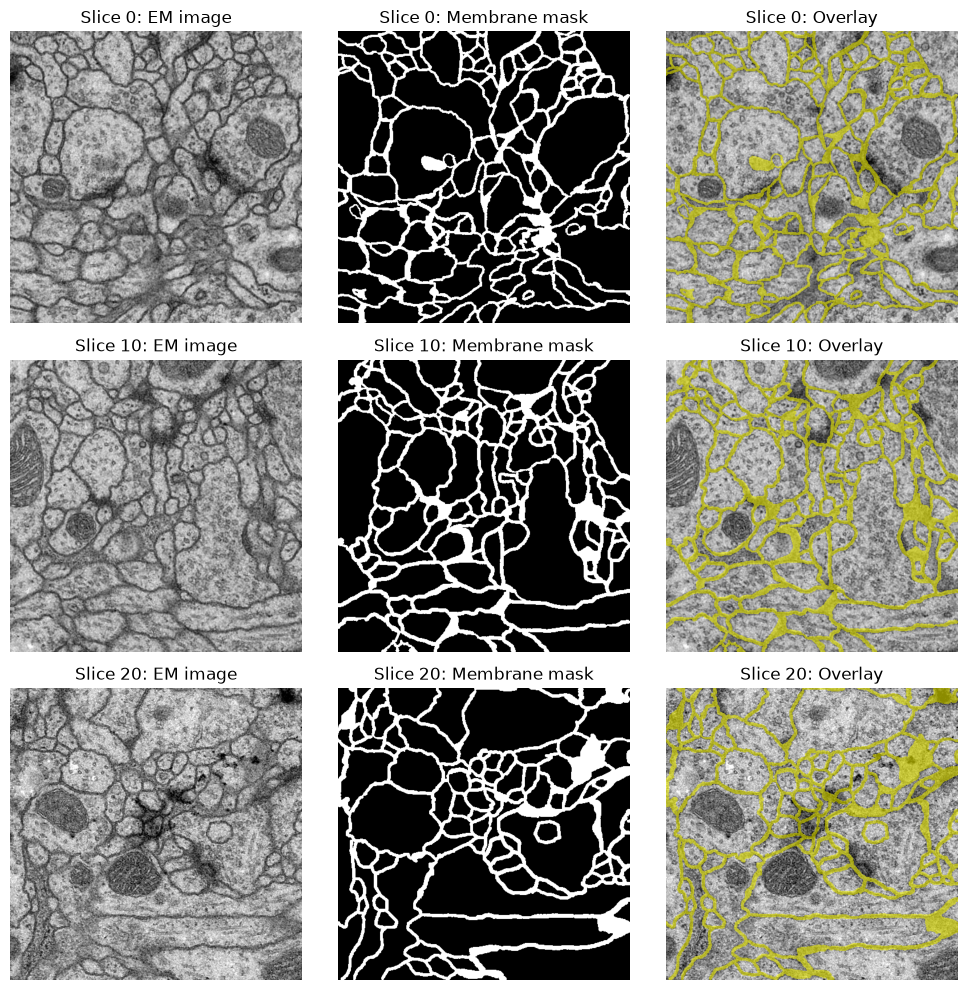

In [2]:
def read_pair(prefix):
    x = load_tiff_stack(DATA / f'{prefix}-volume.tif')
    y = load_tiff_stack(DATA / f'{prefix}-labels.tif')
    assert x.shape == y.shape == (30, 512, 512), (x.shape, y.shape)
    assert x.dtype == np.uint8 and set(np.unique(y)) == {0, 255}, np.unique(y)
    return x, y

raw_images, raw_labels = read_pair('train')
print('Training images:', raw_images.shape, raw_images.dtype)
print('Raw label values:', np.unique(raw_labels))
print('Intensity range:', raw_images.min(), raw_images.max())
# Normalize intensities and encode membranes as class 1.
images = raw_images.astype(np.float32) / 255.0
labels = (raw_labels == 0).astype(np.int64)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, idx in enumerate([0, 10, 20]):
    axes[row, 0].imshow(images[idx], cmap='gray', vmin=0, vmax=1)
    axes[row, 1].imshow(labels[idx], cmap='gray', vmin=0, vmax=1)
    axes[row, 2].imshow(images[idx], cmap='gray', vmin=0, vmax=1)
    overlay = np.ma.masked_where(labels[idx] == 0, labels[idx])
    axes[row, 2].imshow(overlay, cmap='autumn', alpha=.55, vmin=0, vmax=1)
    for col, title in enumerate(['EM image', 'Membrane mask', 'Overlay']):
        axes[row, col].set_title(f'Slice {idx}: {title}')
        axes[row, col].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'isbi_dataset_examples.png', dpi=160, bbox_inches='tight')
plt.show()

## 2. Data split and class balancing
We reserve the last six training slices for validation and keep the official test stack untouched until final evaluation. Adjacent slices are correlated, so this split is not a subject-independent validation. The class weights are inverse frequencies computed exclusively from the 24 training slices.

The original U-Net border weighting uses distances to two separate cell instances. ISBI provides binary membrane annotations, not cell instance IDs. We therefore use only the class-balancing term of the weighted loss for this experiment, rather than treating the two binary classes as cell instances. The instance-based weighting remains demonstrated in notebook 02.

In [3]:
train_images, val_images = images[:24], images[24:]
train_masks, val_masks = labels[:24], labels[24:]
counts = np.bincount(train_masks.ravel(), minlength=2)
assert np.all(counts > 0)
class_weights = (counts.sum() / (2 * counts)).astype(np.float32)
print('Training:', train_images.shape, '| Validation:', val_images.shape)
print(pd.DataFrame({'class': ['Non-membrane', 'Membrane'], 'pixels': counts,
                    'fraction': counts/counts.sum(), 'weight': class_weights}).to_string(index=False))

Training: (24, 512, 512) | Validation: (6, 512, 512)
       class  pixels  fraction   weight
Non-membrane 4873211  0.774576 0.645514
    Membrane 1418245  0.225424 2.218043


## 3. Patch sampling and overlap-tile inference
Our U-Net has no padding in its 3×3 convolutions. The paper's 572×572 input produces 388×388 output. To reduce computational cost, training uses 316×316 input patches and 132×132 target patches. Both dimensions differ by 184 pixels, i.e. 92 pixels of context on each side. The model's actual output shape is checked before training.

Training samples a random target region per slice and reflects the image at its boundaries. Image and mask undergo the same flips, 90° rotations and occasional elastic deformation (σ=10, as in notebook 02). No augmentation is applied to validation/test. For full-slice inference we use 444×444 input tiles with 260×260 output cores, discard the extra rows/columns at the edges, and reconstruct the 512×512 prediction. Input tiles overlap; prediction cores are stitched without averaging. This is an adapted overlap-tile strategy, not an exact recreation of all original inference details.

Input: torch.Size([1, 316, 316]) | Target: torch.Size([132, 132]) | Weight: torch.Size([132, 132])


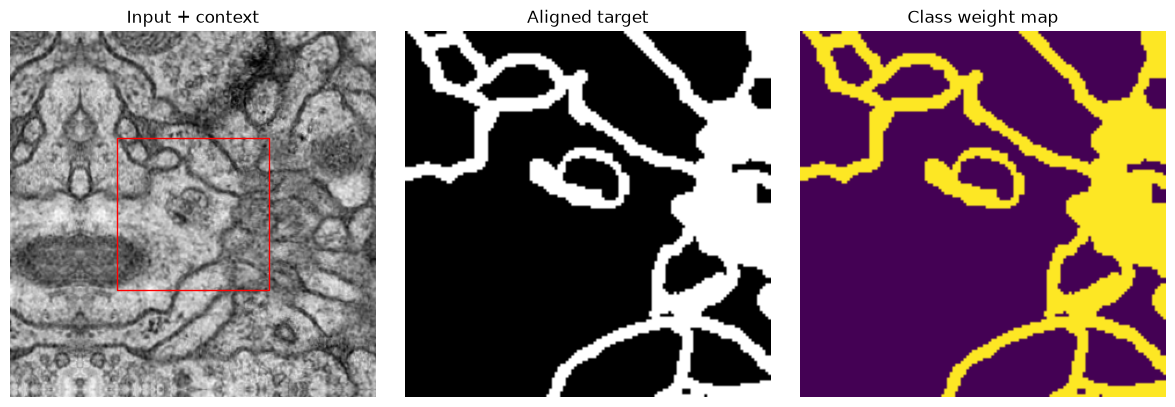

In [4]:
HALO = 92
TRAIN_IN = 316
TRAIN_OUT = TRAIN_IN - 2 * HALO
INFER_IN = 444
INFER_OUT = INFER_IN - 2 * HALO

class ISBIPatchDataset(Dataset):
    def __init__(self, images, masks, patches_per_slice=2):
        self.images = images
        self.masks = masks
        self.patches_per_slice = patches_per_slice
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.images) * self.patches_per_slice

    def __getitem__(self, index):
        i = index // self.patches_per_slice
        image, mask = self.images[i], self.masks[i]
        k = int(self.rng.integers(0, 4))
        image, mask = np.rot90(image, k), np.rot90(mask, k)
        if self.rng.random() < .5:
            image, mask = np.fliplr(image), np.fliplr(mask)
        if self.rng.random() < .5:
            image, mask = elastic_deformation(image, mask, sigma=10,
                                              seed=int(self.rng.integers(0, 2**32)))
        # Reflect missing context, not target labels.
        padded = np.pad(image, HALO, mode='reflect')
        h, w = mask.shape
        y = int(self.rng.integers(0, h - TRAIN_OUT + 1))
        x = int(self.rng.integers(0, w - TRAIN_OUT + 1))
        patch = padded[y:y+TRAIN_IN, x:x+TRAIN_IN]
        target = mask[y:y+TRAIN_OUT, x:x+TRAIN_OUT]
        target = np.ascontiguousarray(target, dtype=np.int64)
        weight = class_weights[target]
        return (torch.from_numpy(np.ascontiguousarray(patch, dtype=np.float32))[None],
                torch.from_numpy(target), torch.from_numpy(weight))

PATCHES_PER_SLICE = 2
train_set = ISBIPatchDataset(train_images, train_masks, PATCHES_PER_SLICE)
train_loader = DataLoader(train_set, batch_size=1, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
patch, target, weight = train_set[0]
assert patch.shape == (1, TRAIN_IN, TRAIN_IN)
assert target.shape == weight.shape == (TRAIN_OUT, TRAIN_OUT)
print('Input:', patch.shape, '| Target:', target.shape, '| Weight:', weight.shape)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(patch[0], cmap='gray'); ax[0].set_title('Input + context')
from matplotlib.patches import Rectangle
ax[0].add_patch(Rectangle((HALO-.5, HALO-.5), TRAIN_OUT, TRAIN_OUT, fill=False, edgecolor='red'))
ax[1].imshow(target, cmap='gray'); ax[1].set_title('Aligned target')
ax[2].imshow(weight, cmap='viridis'); ax[2].set_title('Class weight map')
for a in ax: a.axis('off')
fig.tight_layout(); plt.show()

In [5]:
@torch.inference_mode()
def predict_slice(model, image):
    model.eval()
    h, w = image.shape
    core = INFER_OUT
    out_h = math.ceil(h / core) * core
    out_w = math.ceil(w / core) * core
    padded = np.pad(image, ((HALO, HALO + out_h - h),
                            (HALO, HALO + out_w - w)), mode='reflect')
    probs = np.empty((out_h, out_w), dtype=np.float32)
    for y in range(0, out_h, core):
        for x in range(0, out_w, core):
            patch = padded[y:y+INFER_IN, x:x+INFER_IN]
            tensor = torch.from_numpy(np.ascontiguousarray(patch, dtype=np.float32))[None, None].to(device)
            logits = model(tensor)
            assert logits.shape == (1, 2, core, core), logits.shape
            probs[y:y+core, x:x+core] = logits.softmax(dim=1)[0, 1].cpu().numpy()
    return probs[:h, :w]

## 4. Model, loss and evaluation metrics
We keep the 64–1024 channel architecture, He initialization, dropout, weighted cross-entropy and SGD with momentum 0.99 and batch size 1. Learning rate, number of epochs, patch dimensions and gradient clipping are practical experimental choices. Pixel accuracy, membrane Dice and membrane IoU are computed across pooled pixels (micro-average), with non-membrane IoU also reported. The main selection metric is validation membrane Dice.

In [6]:
def confusion_counts(prob, target):
    pred = prob >= .5
    target = target.astype(bool)
    return np.array([np.count_nonzero(pred & target),
                     np.count_nonzero(pred & ~target),
                     np.count_nonzero(~pred & target),
                     np.count_nonzero(~pred & ~target)], dtype=np.int64)

def metrics_from_counts(counts):
    tp, fp, fn, tn = map(int, counts)
    def ratio(a, b): return a/b if b else 1.0
    iou = ratio(tp, tp+fp+fn)
    bg_iou = ratio(tn, tn+fp+fn)
    return {'dice': ratio(2*tp, 2*tp+fp+fn), 'iou': iou,
            'background_iou': bg_iou, 'mean_iou': (iou+bg_iou)/2,
            'pixel_accuracy': ratio(tp+tn, tp+fp+fn+tn)}

@torch.inference_mode()
def evaluate(model, imgs, masks, description='Evaluation', keep_predictions=False):
    counts = np.zeros(4, dtype=np.int64)
    loss_sum = 0.0
    pixels = 0
    predictions = []
    for image, mask in tqdm(zip(imgs, masks), total=len(imgs), desc=description, leave=False):
        prob = predict_slice(model, image)
        counts += confusion_counts(prob, mask)
        p = np.clip(prob.astype(np.float64), 1e-7, 1-1e-7)
        ce = -np.where(mask == 1, np.log(p), np.log1p(-p))
        loss_sum += np.sum(ce * class_weights[mask])
        pixels += mask.size
        if keep_predictions: predictions.append(prob)
    return {'loss': loss_sum/pixels, **metrics_from_counts(counts)}, predictions

# Sanity check: perfect predictions yield perfect metrics.
assert metrics_from_counts(confusion_counts(np.array([[0., 1.]]), np.array([[0, 1]])))['dice'] == 1.0
model = UNet(in_channels=1, num_classes=2)
model.apply(initialize_weights)
model = model.to(device)
model.eval()
with torch.inference_mode():
    for side, expected in [(TRAIN_IN, TRAIN_OUT), (INFER_IN, INFER_OUT)]:
        dummy = torch.zeros(1, 1, side, side, device=device)
        output = model(dummy)
        assert output.shape == (1, 2, expected, expected), output.shape
        print(f'{side} x {side} -> {tuple(output.shape)}')
        del dummy, output
print('Parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
criterion = WeightedCrossEntropyLoss()
LEARNING_RATE = 1e-3
MOMENTUM = .99
EPOCHS = 5  # Set to 1 for a smoke run; 5 is a short teaching run.
GRAD_CLIP = 5.0
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)
BEST = CHECKPOINTS / 'unet_isbi_best.pth'

316 x 316 -> (1, 2, 132, 132)
444 x 444 -> (1, 2, 260, 260)
Parameters: 31,030,658


## 5. Training
The best checkpoint is selected using validation Dice, not test data. Each epoch samples new training patches. Full validation slices are reconstructed with overlap tiles. The default five epochs are a short demonstration; more epochs may be needed for convergence. If memory is scarce, keep batch size 1, close other notebooks and restart the kernel. The checkpoint contains only model weights and is excluded from Git by the project's `.gitignore`.

In [7]:
history = []
best_dice = -1.0
start = time.perf_counter()
for epoch in range(1, EPOCHS+1):
    model.train()
    train_loss = 0.0
    batches = 0
    bar = tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS}', leave=False)
    for image, mask, weight in bar:
        image, mask, weight = image.to(device), mask.to(device), weight.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(image)
        assert logits.shape[-2:] == mask.shape[-2:]
        loss = criterion(logits, mask, weight)
        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite loss; restart with a lower learning rate.')
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        train_loss += loss.item()
        batches += 1
        bar.set_postfix(loss=f'{train_loss/batches:.4f}')
    optimizer.zero_grad(set_to_none=True)
    # Release training tensors before evaluation.
    del image, mask, weight, logits, loss
    val, _ = evaluate(model, val_images, val_masks, 'Validation')
    row = {'epoch': epoch, 'train_loss': train_loss/batches,
           **{f'val_{k}': v for k, v in val.items()}}
    history.append(row)
    if val['dice'] > best_dice:
        best_dice = val['dice']
        torch.save(model.state_dict(), BEST)
        best_epoch = epoch
    pd.DataFrame(history).to_csv(RESULTS / 'unet_training_history.csv', index=False)
    print(f"Epoch {epoch:02d} | train loss {row['train_loss']:.4f} | "
          f"val loss {val['loss']:.4f} | Dice {val['dice']:.4f} | IoU {val['iou']:.4f}")
print(f'Best epoch: {best_epoch} | Training + validation: {(time.perf_counter()-start)/60:.1f} min')
log = pd.DataFrame(history)
display(log.round(4))

Epoch 1/5:   0%|          | 0/48 [00:00<?, ?it/s]

Validation:   0%|          | 0/6 [00:00<?, ?it/s]

Epoch 01 | train loss 0.6855 | val loss 0.5453 | Dice 0.5657 | IoU 0.3944


Epoch 2/5:   0%|          | 0/48 [00:00<?, ?it/s]

Validation:   0%|          | 0/6 [00:00<?, ?it/s]

Epoch 02 | train loss 0.5640 | val loss 0.5628 | Dice 0.5385 | IoU 0.3685


... (6 outputs left out)

Epoch 5/5:   0%|          | 0/48 [00:00<?, ?it/s]

Validation:   0%|          | 0/6 [00:00<?, ?it/s]

Epoch 05 | train loss 0.4780 | val loss 0.4049 | Dice 0.6079 | IoU 0.4366
Best epoch: 4 | Training + validation: 0.8 min


,epoch,train_loss,val_loss,val_dice,val_iou,val_background_iou,val_mean_iou,val_pixel_accuracy
0,1,0.6855,0.5453,0.5657,0.3944,0.7508,0.5726,0.7856
1,2,0.5640,0.5628,0.5385,0.3685,0.6204,0.4944,0.6892
2,3,0.5728,0.4444,0.6132,0.4422,0.8360,0.6391,0.8548
3,4,0.5298,0.4381,0.6232,0.4526,0.8087,0.6307,0.8348
4,5,0.4780,0.4049,0.6079,0.4366,0.7294,0.5830,0.7763


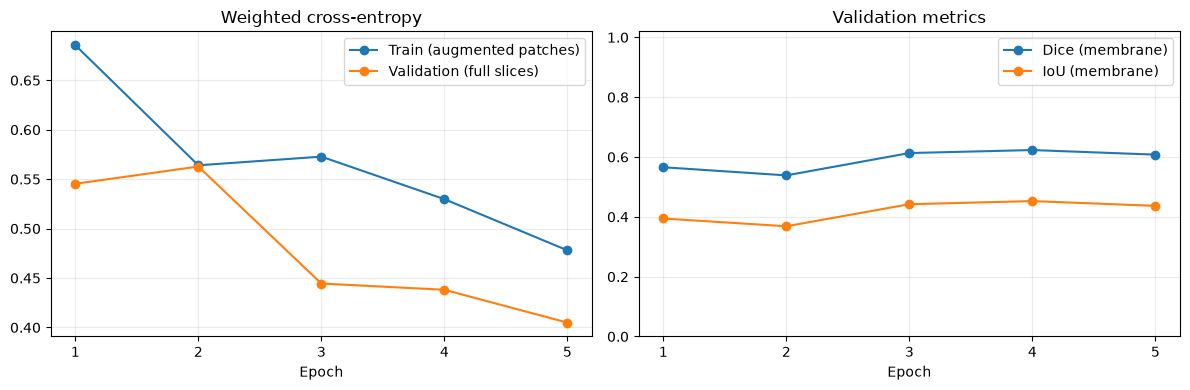

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(log.epoch, log.train_loss, 'o-', label='Train (augmented patches)')
axes[0].plot(log.epoch, log.val_loss, 'o-', label='Validation (full slices)')
axes[0].set_title('Weighted cross-entropy'); axes[0].legend()
axes[1].plot(log.epoch, log.val_dice, 'o-', label='Dice (membrane)')
axes[1].plot(log.epoch, log.val_iou, 'o-', label='IoU (membrane)')
axes[1].set_title('Validation metrics'); axes[1].set_ylim(0, 1.02); axes[1].legend()
for ax in axes:
    ax.set_xlabel('Epoch'); ax.grid(alpha=.25)
    ax.set_xticks(log.epoch)
fig.tight_layout()
fig.savefig(RESULTS / 'unet_learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Final evaluation on the test stack
Only now load the provided test images and their annotations. Use the best validation checkpoint without adjusting threshold or hyperparameters on the test results. These are local semantic-segmentation scores, not the challenge's Rand/warping leaderboard scores. The test labels are assumed to be the corresponding labels distributed with the downloaded archive; shape and value checks below do not independently establish their provenance.

In [9]:
model.load_state_dict(torch.load(BEST, map_location='cpu', weights_only=True))
model.eval()
raw_test, raw_test_labels = read_pair('test')
test_images = raw_test.astype(np.float32) / 255.0
test_masks = (raw_test_labels == 0).astype(np.int64)

test_metrics, test_probs = evaluate(model, test_images, test_masks, 'Test', keep_predictions=True)
print('Best validation epoch:', best_epoch)
score_table = pd.DataFrame([test_metrics], index=['ISBI test stack'])
display(score_table.round(4))
score_table.to_csv(RESULTS / 'unet_test_metrics.csv')
per_slice = pd.DataFrame([{'slice': i, **metrics_from_counts(confusion_counts(p, m))}
                          for i, (p, m) in enumerate(zip(test_probs, test_masks))])
per_slice.to_csv(RESULTS / 'unet_test_per_slice.csv', index=False)
print('Test slices:', len(test_probs), '| Prediction shape:', test_probs[0].shape)

Test:   0%|          | 0/30 [00:00<?, ?it/s]

Best validation epoch: 4


,loss,dice,iou,background_iou,mean_iou,pixel_accuracy
ISBI test stack,0.6163,0.6231,0.4525,0.7512,0.6019,0.7937


Test slices: 30 | Prediction shape: (512, 512)


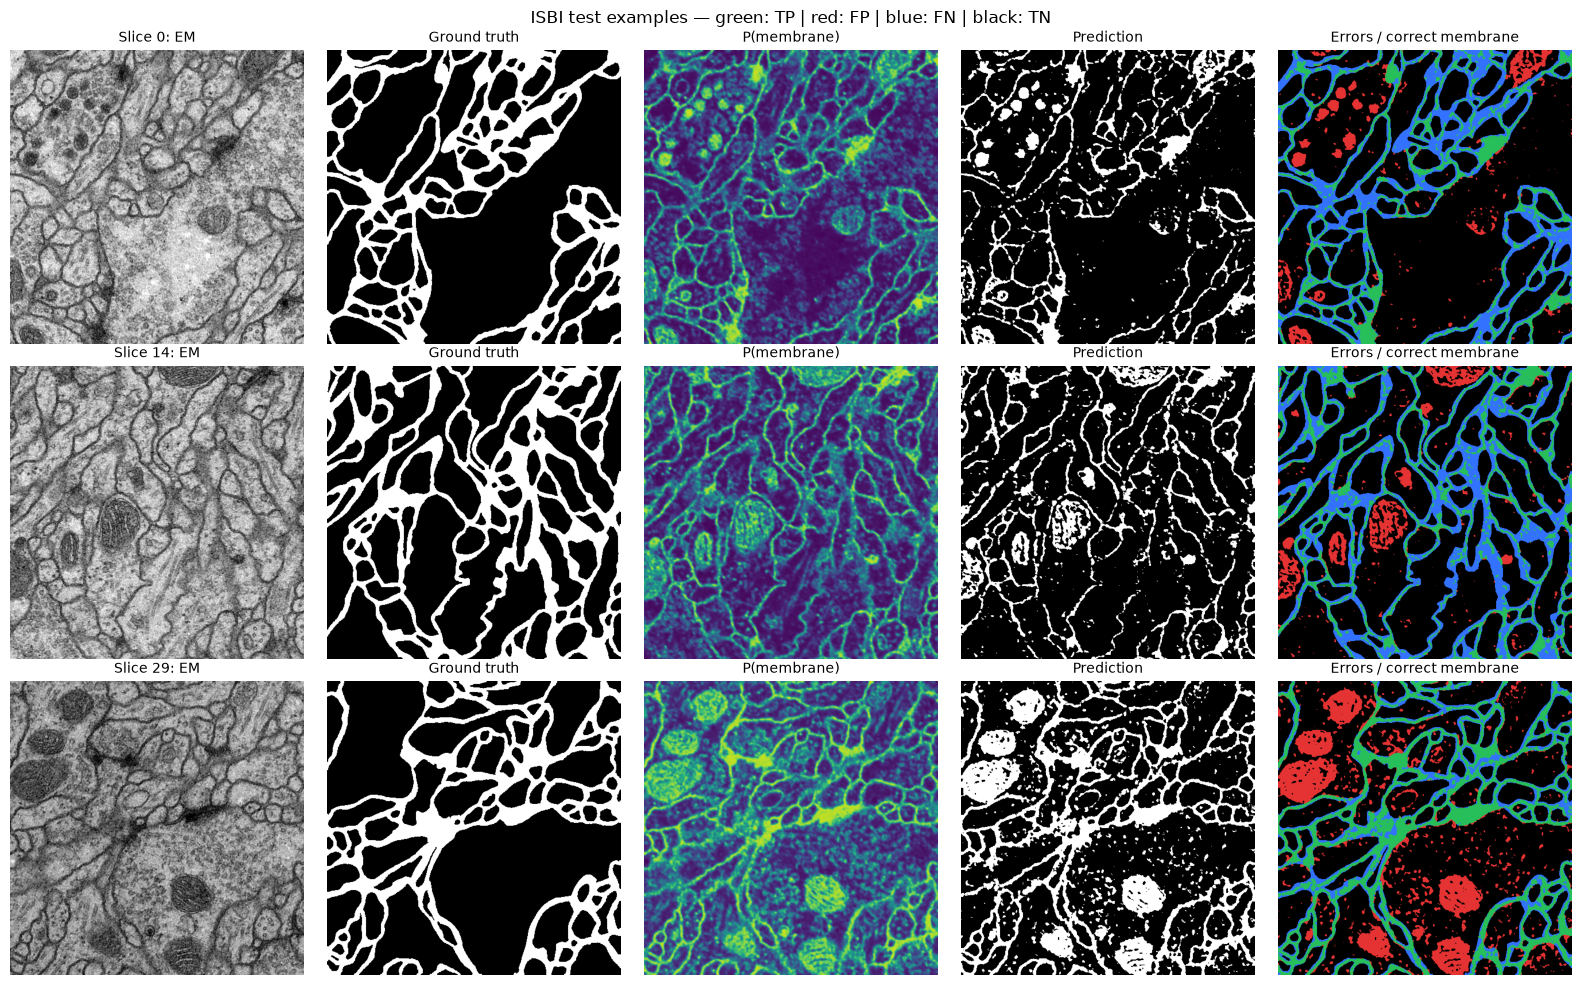

In [10]:
# Fixed examples, not selected based on performance.
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for row, idx in enumerate([0, 14, 29]):
    image, truth, prob = test_images[idx], test_masks[idx], test_probs[idx]
    pred = prob >= .5
    error = np.zeros((*truth.shape, 3), dtype=np.float32)
    error[(pred == 1) & (truth == 1)] = [0.15, .75, .35]  # TP green
    error[(pred == 1) & (truth == 0)] = [.9, .2, .2]     # FP red
    error[(pred == 0) & (truth == 1)] = [.2, .45, 1.]    # FN blue
    for col, (arr, title, cmap) in enumerate([
            (image, f'Slice {idx}: EM', 'gray'), (truth, 'Ground truth', 'gray'),
            (prob, 'P(membrane)', 'viridis'), (pred, 'Prediction', 'gray'),
            (error, 'Errors / correct membrane', None)]):
        axes[row, col].imshow(arr, cmap=cmap, vmin=0, vmax=1)
        axes[row, col].set_title(title, fontsize=10); axes[row, col].axis('off')
fig.suptitle('ISBI test examples — green: TP | red: FP | blue: FN | black: TN')
fig.tight_layout()
fig.savefig(RESULTS / 'unet_test_predictions.png', dpi=170, bbox_inches='tight')
plt.show()

## 7. Interpretation and limits
The following cell generates a factual summary from the actual run. Inspect the curves and error maps to discuss convergence, false positives and missing membrane pixels. A high Dice or IoU does not guarantee correct neuronal topology; official ISBI metrics and connected-region analysis would be needed to assess that aspect.

Compared with the paper, this experiment uses a short training schedule, smaller patches, per-class balancing only, no test-time rotation ensemble, and different evaluation metrics. The validation stack consists of adjacent slices from the same volume, and the independent test stack may also originate from the same specimen. Generalization to other animals or imaging conditions is not established.

In [11]:
summary = {
    'seed': SEED, 'device': str(device), 'epochs': EPOCHS,
    'best_epoch': int(best_epoch), 'training_slices': len(train_images),
    'validation_slices': len(val_images), 'test_slices': len(test_images),
    'training_patch': TRAIN_IN, 'target_patch': TRAIN_OUT,
    'inference_patch': INFER_IN, 'learning_rate': LEARNING_RATE,
    'momentum': MOMENTUM, 'patches_per_slice': PATCHES_PER_SLICE,
    'class_weights': class_weights.tolist(),
    'best_validation_dice': float(best_dice),
    'test_metrics': {k: float(v) for k, v in test_metrics.items()}
}
(RESULTS / 'unet_experiment_summary.json').write_text(json.dumps(summary, indent=2))
print(f"Best validation Dice: {best_dice:.4f} (epoch {best_epoch})")
print(f"Test membrane Dice: {test_metrics['dice']:.4f}")
print(f"Test membrane IoU: {test_metrics['iou']:.4f}")
print(f"Test pixel accuracy: {test_metrics['pixel_accuracy']:.4f}")
print('Results saved:', RESULTS)
print('Best model:', BEST)

Best validation Dice: 0.6232 (epoch 4)
Test membrane Dice: 0.6231
Test membrane IoU: 0.4525
Test pixel accuracy: 0.7937
Results saved: /Users/mac/Desktop/TPs/S3/Generative/Synthèse UNET/results
Best model: /Users/mac/Desktop/TPs/S3/Generative/Synthèse UNET/checkpoints/unet_isbi_best.pth
